# **Business Case: Scaler - Clustering**

**1.Define Problem Statement and perform Exploratory Data Analysis**



In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
url = "https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/002/492/original/ola_driver_scaler.csv"
df = pd.read_csv(url)

# 1. Observations on shape, data types, and missing values
print("Shape of data:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())



Shape of data: (19104, 14)

Data Types:
 Unnamed: 0                int64
MMM-YY                   object
Driver_ID                 int64
Age                     float64
Gender                  float64
City                     object
Education_Level           int64
Income                    int64
Dateofjoining            object
LastWorkingDate          object
Joining Designation       int64
Grade                     int64
Total Business Value      int64
Quarterly Rating          int64
dtype: object

Missing Values:
 Unnamed: 0                  0
MMM-YY                      0
Driver_ID                   0
Age                        61
Gender                     52
City                        0
Education_Level             0
Income                      0
Dateofjoining               0
LastWorkingDate         17488
Joining Designation         0
Grade                       0
Total Business Value        0
Quarterly Rating            0
dtype: int64


In [ ]:
# Convert date-like features to datetime
df['MMM-YY'] = pd.to_datetime(df['MMM-YY'])
df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'])
df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'])

# Statistical Summary
display(df.describe(include='all'))



,Unnamed: 0,MMM-YY,Driver_ID,Age,Gender,City,Education_Level,Income,Dateofjoining,LastWorkingDate,Joining Designation,Grade,Total Business Value,Quarterly Rating
count,19104.000000,19104,19104.000000,19043.000000,19052.000000,19104,19104.000000,19104.000000,19104,1616,19104.000000,19104.000000,1.910400e+04,19104.000000
unique,NaN,NaN,NaN,NaN,NaN,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,C20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,9551.500000,2019-12-11 02:09:29.849246464,1415.591133,34.668435,0.418749,NaN,1.021671,65652.025126,2018-04-28 20:52:54.874371840,2019-12-21 20:59:06.534653696,1.690536,2.252670,5.716621e+05,2.008899
min,0.000000,2019-01-01 00:00:00,1.000000,21.000000,0.000000,NaN,0.000000,10747.000000,2013-04-01 00:00:00,2018-12-31 00:00:00,1.000000,1.000000,-6.000000e+06,1.000000
25%,4775.750000,2019-06-01 00:00:00,710.000000,30.000000,0.000000,NaN,0.000000,42383.000000,2016-11-29 12:00:00,2019-06-06 00:00:00,1.000000,1.000000,0.000000e+00,1.000000
50%,9551.500000,2019-12-01 00:00:00,1417.000000,34.000000,0.000000,NaN,1.000000,60087.000000,2018-09-12 00:00:00,2019-12-20 12:00:00,1.000000,2.000000,2.500000e+05,2.000000
75%,14327.250000,2020-07-01 00:00:00,2137.000000,39.000000,1.000000,NaN,2.000000,83969.000000,2019-11-05 00:00:00,2020-07-03 00:00:00,2.000000,3.000000,6.997000e+05,3.000000
max,19103.000000,2020-12-01 00:00:00,2788.000000,58.000000,1.000000,NaN,2.000000,188418.000000,2020-12-28 00:00:00,2020-12-28 00:00:00,5.000000,5.000000,3.374772e+07,4.000000


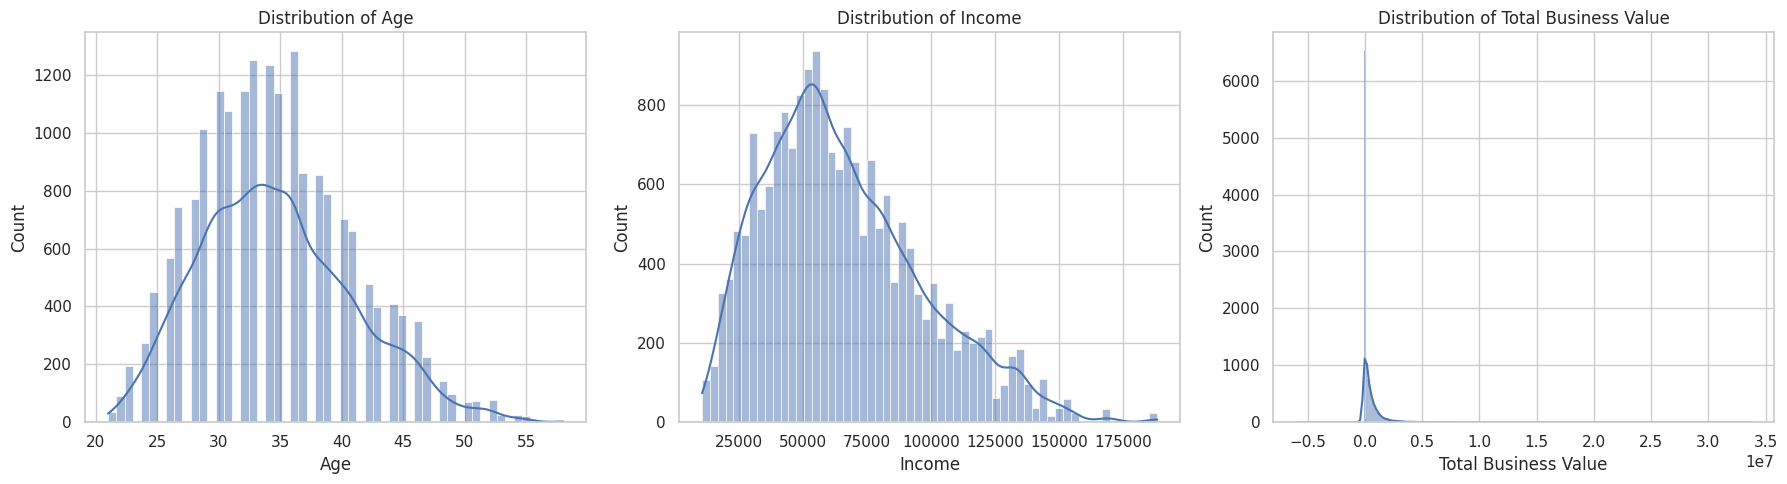

In [ ]:
# 2. Univariate Analysis
numerical_cols = ['Age', 'Income', 'Total Business Value']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()



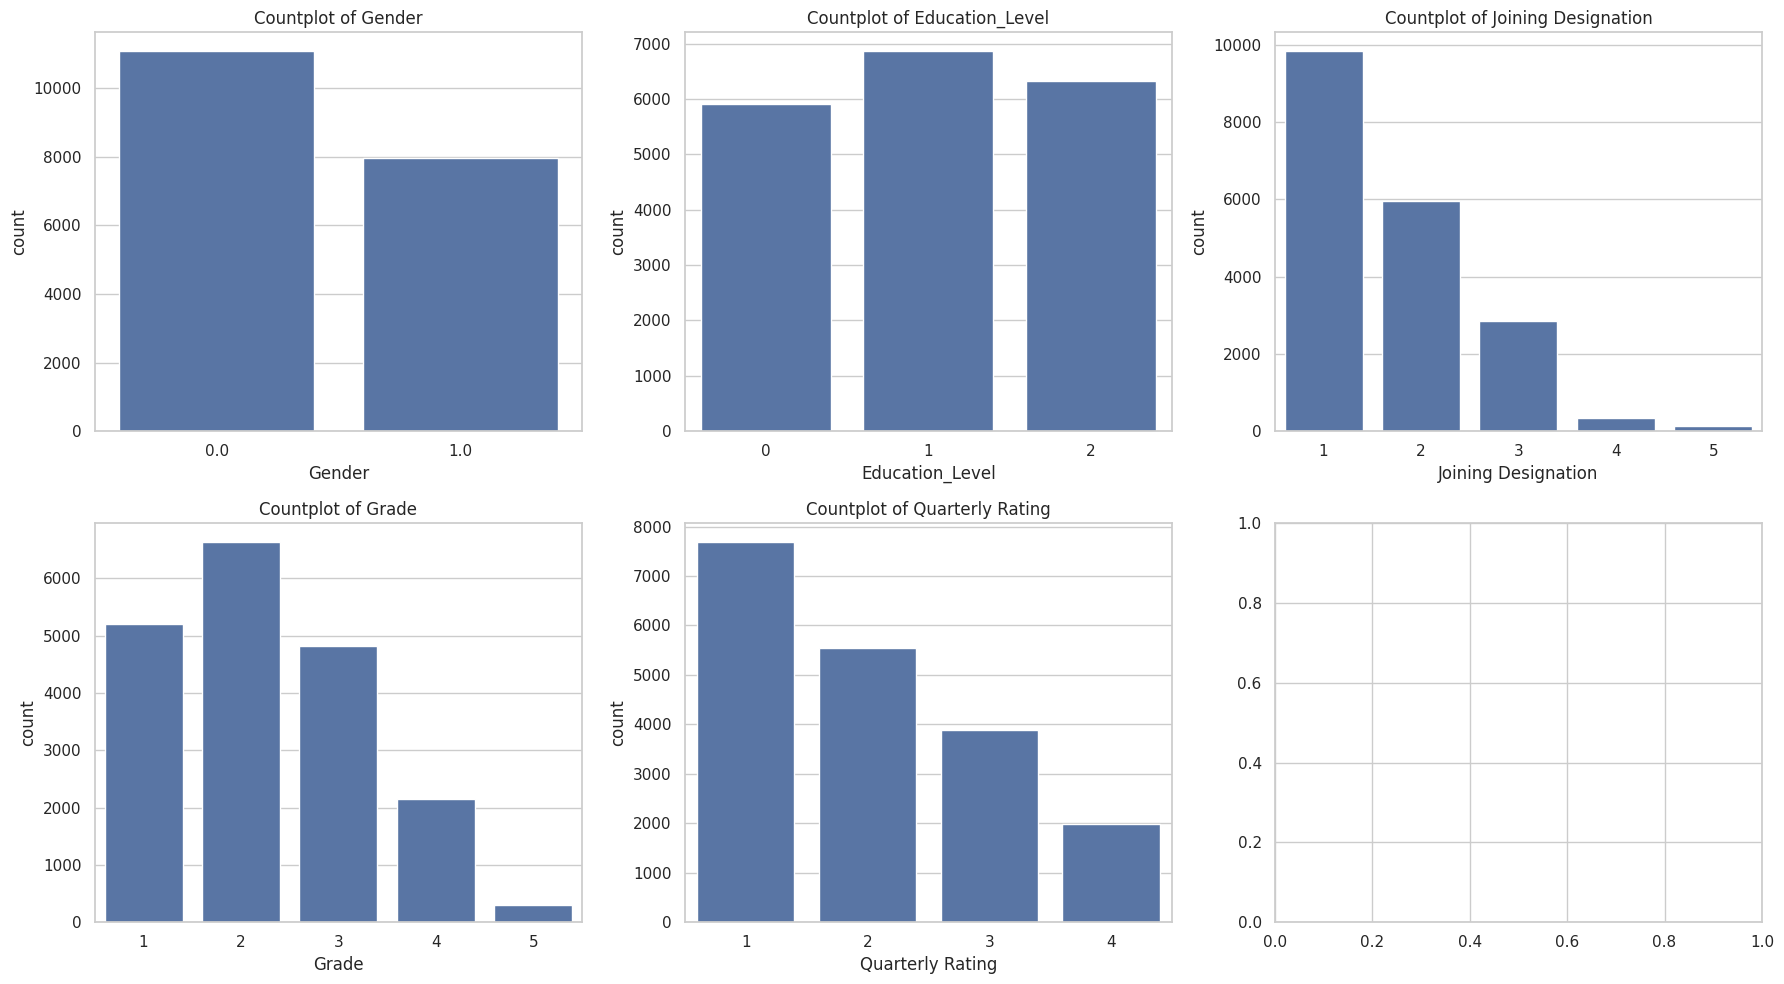

In [ ]:
categorical_cols = ['Gender', 'Education_Level', 'Joining Designation', 'Grade', 'Quarterly Rating']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=df, ax=axes[i])
    axes[i].set_title(f'Countplot of {col}')
plt.tight_layout()
plt.show()



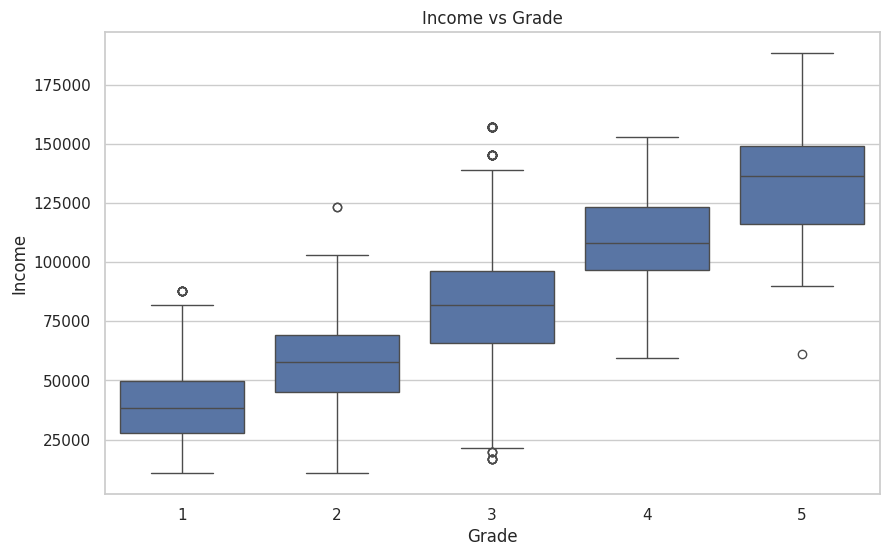

In [ ]:
# 3. Bivariate Analysis
# (Assuming we will look at relationships before aggregation, e.g., Grade vs Income)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Grade', y='Income', data=df)
plt.title('Income vs Grade')
plt.show()

**Step 2: Data Preprocessing**

In [ ]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Feature Engineering & Aggregation at Driver_ID level
# Group by Driver_ID to extract features
df_grouped = df.groupby('Driver_ID').agg(
    Age=('Age', 'max'),
    Gender=('Gender', 'first'),
    City=('City', 'first'),
    Education_Level=('Education_Level', 'last'),
    Income_first=('Income', 'first'),
    Income_last=('Income', 'last'),
    Joining_Designation=('Joining Designation', 'last'),
    Grade=('Grade', 'last'),
    Total_Business_Value=('Total Business Value', 'sum'),
    Rating_first=('Quarterly Rating', 'first'),
    Rating_last=('Quarterly Rating', 'last'),
    LastWorkingDate=('LastWorkingDate', 'last')
).reset_index()

# Target Variable Creation: 1 if LastWorkingDate is present (left), 0 otherwise
df_grouped['Target'] = df_grouped['LastWorkingDate'].notnull().astype(int)

# Create feature: 1 if rating increased, else 0
df_grouped['Rating_Increased'] = (df_grouped['Rating_last'] > df_grouped['Rating_first']).astype(int)

# Create feature: 1 if income increased, else 0
df_grouped['Income_Increased'] = (df_grouped['Income_last'] > df_grouped['Income_first']).astype(int)

# Drop intermediate columns and LastWorkingDate
df_grouped.drop(['Income_first', 'Income_last', 'Rating_first', 'Rating_last', 'LastWorkingDate'], axis=1, inplace=True)

# 2. KNN Imputation for Missing Values (Numerical Features)
# Identify columns with missing values (e.g., Age, Gender)
impute_cols = ['Age', 'Gender']
imputer = KNNImputer(n_neighbors=5)
df_grouped[impute_cols] = imputer.fit_transform(df_grouped[impute_cols])

# 3. Encoding Categorical Variables (One-Hot Encoding)
df_encoded = pd.get_dummies(df_grouped, columns=['City', 'Gender'], drop_first=True)

# Prepare Features (X) and Target (y)
X = df_encoded.drop(['Driver_ID', 'Target'], axis=1)
y = df_encoded['Target']

# 4. Class Imbalance Treatment (SMOTE)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# 5. Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_resampled)

Step 3: Model Building

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_resampled, test_size=0.2, random_state=42)

# 1. Ensemble - Bagging Algorithm (Random Forest)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 2. Ensemble - Boosting Algorithm (Gradient Boosting)
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

**Step 4: Results Evaluation**

--- Evaluation for Random Forest (Bagging) ---

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.79      0.81       326
           1       0.79      0.83      0.81       321

    accuracy                           0.81       647
   macro avg       0.81      0.81      0.81       647
weighted avg       0.81      0.81      0.81       647


Confusion Matrix:
 [[257  69]
 [ 55 266]]

ROC AUC Score: 0.8841


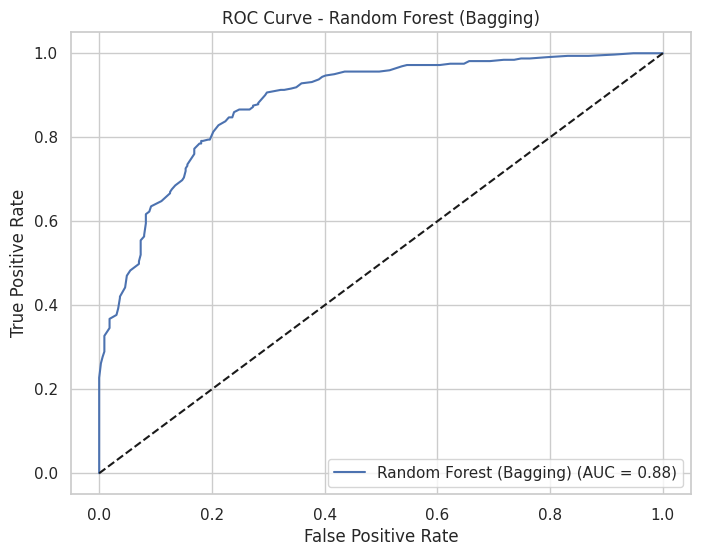

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

def evaluate_model(y_true, y_pred, y_prob, model_name):
    print(f"--- Evaluation for {model_name} ---")
    print("\nClassification Report:\n", classification_report(y_true, y_pred))
    print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))

    auc = roc_auc_score(y_true, y_prob)
    print(f"\nROC AUC Score: {auc:.4f}")

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend()
    plt.show()

# Evaluate Random Forest
evaluate_model(y_test, y_pred_rf, y_prob_rf, "Random Forest (Bagging)")



--- Evaluation for Gradient Boosting ---

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.65      0.73       326
           1       0.71      0.87      0.78       321

    accuracy                           0.76       647
   macro avg       0.77      0.76      0.76       647
weighted avg       0.77      0.76      0.76       647


Confusion Matrix:
 [[212 114]
 [ 41 280]]

ROC AUC Score: 0.8427


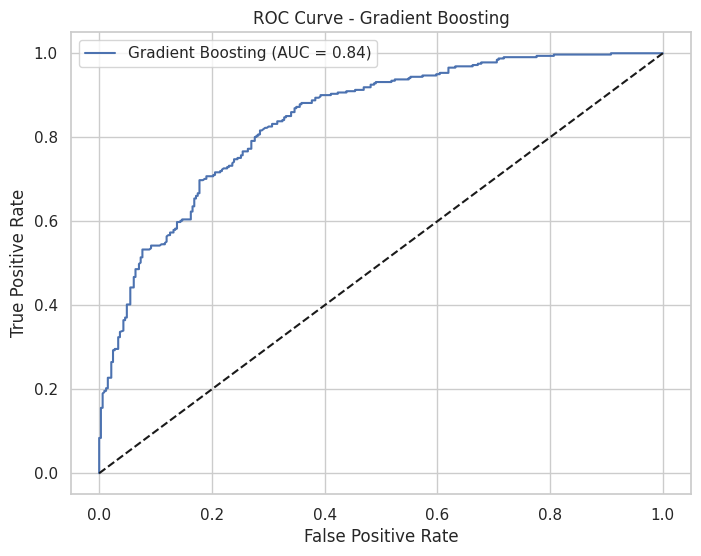

In [ ]:
# Evaluate Gradient Boosting
evaluate_model(y_test, y_pred_gb, y_prob_gb, "Gradient Boosting")

**Step 5: Actionable Insights & Recommendations**



*   **Financial Stagnation Drives Churn:** If the engineered feature Income_Increased shows high importance, Ola should consider restructuring payout models to ensure consistent financial growth for drivers over time.

*  **Performance Recognition:** If a lack of increase in Quarterly Rating correlates with churn, the company might need to improve how it communicates feedback or reward drivers for maintaining high ratings.

*  **Early Tenure Attrition:** If drivers with lower grades or specific joining designations are churning rapidly, Ola should focus on optimizing the onboarding process and expectations during the initial 3-6 months.

*  **Recommendation:** Implement a proactive alert system using this predictive model. When a driver's probability of churning crosses a certain threshold (e.g., 70%), automatically trigger a retention workflow (e.g., a bonus offer, a feedback call, or a better route assignment).


